In [71]:
import time
from Raspbot_Lib import Raspbot
import sys
sys.path.append('/home/pi/project_demo/lib')
from McLumk_Wheel_Sports import *

In [8]:
bot = Raspbot()

move_forward(20)
time.sleep(3)
move_left(20)
time.sleep(1)
move_backward(20)
time.sleep(1)
move_right(20)
time.sleep(1)
stop_robot()

del bot

In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

OpenCV: 4.10.0
NumPy: 1.23.5


In [16]:
# Importing
COLORS = {
    "red": [
        (np.array([0, 43, 46]), np.array([10, 255, 255])),
        (np.array([156, 43, 46]), np.array([180, 255, 255]))
    ],
    "yellow": [
        (np.array([26, 43, 46]), np.array([34, 255, 255]))
    ],
    "green": [
        (np.array([35, 43, 46]), np.array([77, 255, 255]))
    ],
    "blue": [
        (np.array([100, 43, 46]), np.array([124, 255, 255]))
    ]
}

MIN_PIXELS = 500

def ColorCounter(image):

    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    color_counts = {}

    for color, ranges in COLORS.items():
        total = 0
        for lower, upper in ranges:
            mask = cv2.inRange(hsv, lower, upper)
            total += cv2.countNonZero(mask)
        
        color_counts[color] = total

    return color_counts

def ColorLocator(image, color_counts):
    
    # Return if colorCounter didn't work
    if not color_counts:
        return None

    color = max(color_counts, key=color_counts.get)

    if color_counts[color] < MIN_PIXELS:
        return None

    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    mask = np.zeros(hsv.shape[:2], dtype=np.uint8)

    for lower, upper in COLORS[color]:
        color_mask = cv2.inRange(hsv, lower, upper)
        mask = cv2.bitwise_or(mask, color_mask)

    ys, xs = np.where(mask > 0)

    if len(xs) == 0:
        return None

    center_x = np.mean(xs)
    center_y = np.mean(ys)

    height, width = image.shape[:2]

    x = (center_x - width / 2) / (width / 2)
    y = (center_y - height / 2) / (height / 2)

    return (x, y, color)

Camera frame shape: (480, 640, 3)


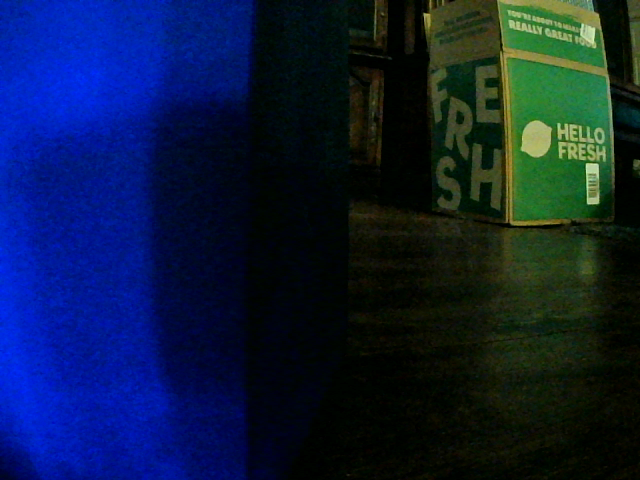

In [72]:
# Camera takes a snapshot (testing camera)
import cv2

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    raise RuntimeError("Could not open RASPBOT camera")

ret, frame = cap.read()

if ret:
    print("Camera frame shape:", frame.shape)
    display(__import__("PIL").Image.fromarray(
        cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    ))
else:
    print("Could not read camera frame")

cap.release()

Camera test stopped


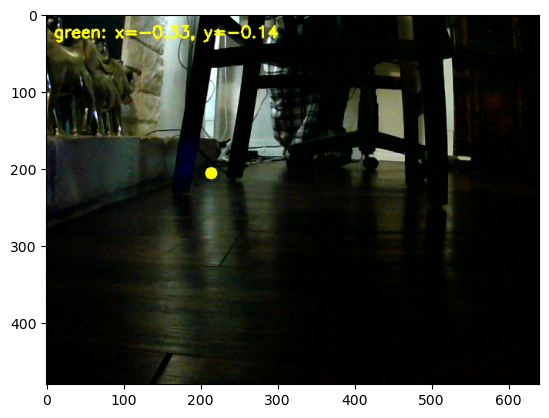

In [97]:
# Testing colorCounter and colorLocator. Shows main colors and its center live. 
# Feel free to use to check camera.

import cv2
import time
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    raise RuntimeError("Could not open RASPBOT camera")

try:
    while True:
        ret, frame = cap.read()

        if not ret:
            print("Failed to read camera frame")
            break

        counts = ColorCounter(frame)
        position = ColorLocator(frame, counts)

        # Annotate the live frame
        display_frame = frame.copy()

        if position is not None:
            x, y, color = position
            h, w = frame.shape[:2]

            px = int((x + 1) * w / 2)
            py = int((y + 1) * h / 2)

            cv2.circle(display_frame, (px, py), 8, (0, 255, 255), -1)
            cv2.putText(
                display_frame,
                f"{color}: x={x:.2f}, y={y:.2f}",
                (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (0, 255, 255),
                2
            )
        else:
            cv2.putText(
                display_frame,
                "No command color detected",
                (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (255, 255, 255),
                2
            )

        print("Pixel counts:", counts)
        clear_output(wait=True)
        display(plt.imshow(cv2.cvtColor(display_frame, cv2.COLOR_BGR2RGB)).get_figure())
        plt.axis("off")
        plt.show()

        time.sleep(0.05)

except KeyboardInterrupt:
    print("Camera test stopped")

finally:
    cap.release()

In [ ]:
def cameraCapture():
    import cv2
    from PIL import Image
    from IPython.display import display

    cap = cv2.VideoCapture(0)

    try:
        if not cap.isOpened():
            raise RuntimeError("Could not open RASPBOT camera")

        ret, frame = cap.read()

        if not ret:
            raise RuntimeError("Could not capture camera frame")

    finally:
        cap.release()
        return frame

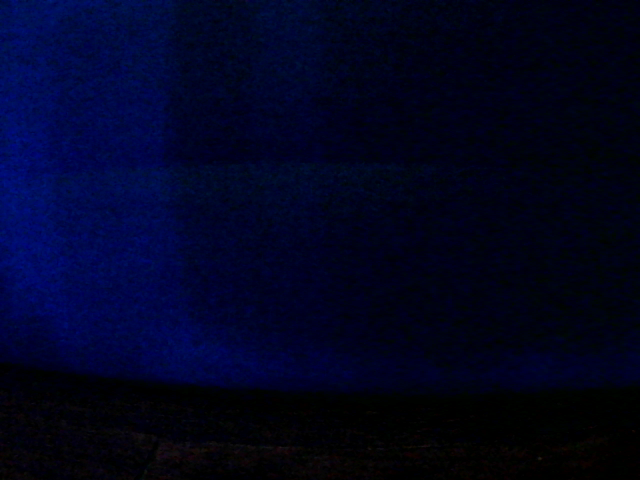

Color counts: {'red': 0, 'yellow': 0, 'green': 0, 'blue': 80803}
Detected position: (-0.621816485774043, -0.18351680424406686, 'blue')
Target centered.


In [99]:
# Test to check BlueAction.

from McLumk_Wheel_Sports import *
import time

FL,FR,RL,RR = 0,1,2,3

def set_wheels(fl,fr,rl,rr):
	bot.Ctrl_Muto(FL,fl)
	bot.Ctrl_Muto(FR,fr)
	bot.Ctrl_Muto(RL,rl)
	bot.Ctrl_Muto(RR,rr)

def stop_all():
	set_wheels(0,0,0,0)

def BlueAction(p_vector):
    """
    Move until the command object is centered.
    """
    if p_vector is None:
        stop_all()
        return

    tolerance = 0.25

    try:
        while True:
            # Check if the camera lost the object
            if p_vector is None:
                print("Lost target object. Stopping.")
                break

            x = p_vector[0]

            # Check if object is within tolerance of the center
            if abs(x) <= tolerance:
                print("Target centered.")
                break

            if p_vector[2] != "blue":
                print("Lost target object. Stopping.")
                break

            # Speed proportional to how far the object is from center
            speed = max(int(0.5 * abs(x)), 5)
            #speed = min(max(speed, 10), 60)
            #speed = 10

            if x > 0:
                #move_right(speed)
                move_left(speed)
            else:
                #move_left(speed)
                move_right(speed)

            # Short sleep to prevent overshooting
            time.sleep(0.05)

            # Capture new frame and update position vector
            frame = cameraCapture()
            p_vector = ColorLocator(frame, color_counts)

    finally:
        # Guarantee motors always stop, even if an error occurs or the loop breaks
        stop_all()

import cv2
from PIL import Image
from IPython.display import display

frame = cameraCapture()

display(Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)))

# Detect command colors
color_counts = ColorCounter(frame)
print("Color counts:", color_counts)

# Locate the most prominent color
p_vector = ColorLocator(frame, color_counts)
print("Detected position:", p_vector)

if p_vector is not None and p_vector[2] == "blue":
    BlueAction(p_vector)
else:
    stop_all()

